# 1. Entendimento do negócio

**Qual problema de negócio está sendo resolvido?**
O problema central é a reatividade da empresa em relação à satisfação do consumidor, uma vez que o NPS atualmente é coletado apenas após o encerramento da jornada de compra. O projeto busca resolver a incapacidade do e-commerce de antecipar problemas, transformando dados operacionais em insights para agir de forma preventiva e proativa na experiência do cliente, antes mesmo da aplicação da pesquisa.

**Por que o NPS é importante para um e-commerce?**
Em um cenário de crescimento acelerado e alta variabilidade na satisfação, o NPS atua como o principal termômetro da lealdade do cliente.

**Quais áreas poderiam se beneficiar desses insights?**
Todas as áreas podem se beneficiar. Exemplo:
- **Logística:** Mapeando gargalos operacionais, como o limite exato de dias de atraso que transforma um cliente neutro em um detrator.
- **Atendimento:** Avaliando se a rapidez na resolução de chamados consegue reverter uma insatisfação causada por falhas na entrega.
- **Produto e Pricing:** Entendendo se o ticket médio, descontos aplicados ou valor de frete influenciam a percepção geral de valor da compra.
- **Estratégia:** Direcionando e priorizando investimentos operacionais baseados nos fatores que estatisticamente mais elevam a satisfação do consumidor.

**Reflexão: Como o NPS impacta:**
- **Recompra:** O NPS reflete o nível de lealdade do consumidor, e clientes classificados como promotores apresentam uma propensão significativamente maior a retornar à loja para novas compras. Isso garante a previsibilidade de receita e aumenta o Lifetime Value (LTV) da base, enquanto detratores representam perda de faturamento futuro, pois raramente dão uma segunda chance após uma experiência ruim.
- **Boca a boca:** Em um ambiente digital, a reputação é um ativo crítico. Promotores atuam como defensores da marca, gerando marketing orgânico positivo e reduzindo o Custo de Aquisição de Clientes (CAC) por meio de recomendações a amigos e familiares. Em contrapartida, detratores tendem a vocalizar suas frustrações em redes sociais e plataformas de avaliação, o que afasta potenciais novos compradores e prejudica a credibilidade do negócio.
- **Market share em e-commerce:** O varejo online é um setor com barreiras de troca muito baixas, onde o concorrente está a apenas um clique de distância. Manter um NPS elevado é o que blinda a base atual de clientes contra as investidas de rivais, garantindo a retenção e permitindo o crescimento sustentável da fatia de mercado da empresa (market share) em meio a um cenário altamente competitivo.

**Quais indicadores de mercado poderiam complementar essa análise?**
Para que a avaliação interna ganhe contexto estratégico, é fundamental cruzar os dados da operação com a realidade do setor.
- **Benchmarks de NPS:** Comparar o score da empresa com a média do segmento de e-commerce permite entender se a nota atual é um diferencial competitivo ou um sinal de alerta de defasagem perante o mercado.
- **SLA Logístico de mercado:** Monitorar o nível de serviço e os prazos médios praticados pelas principais transportadoras do mercado. Se a concorrência estabelece um padrão de entrega expressa, um SLA interno longo pode gerar detratores mesmo quando cumprido rigorosamente, pois a expectativa do consumidor já foi alterada pelo mercado.
- **Dados da Concorrência:** Acompanhar políticas de devolução, campanhas de frete grátis e tempos médios de resposta nos canais de atendimento dos principais rivais. A percepção de satisfação e o rigor do cliente ao dar uma nota são diretamente moldados pelas melhores experiências que ele encontra em outras plataformas.

# 2. Definição da Target

**Qual variável representa a satisfação do cliente?**
A variável que representa o target deste problema de negócio é a `nps_score`. Ela armazena a nota de satisfação do cliente, que varia em uma escala contínua de 0 a 10.

**Por que ela foi escolhida?**
Ela foi escolhida porque é o principal indicador de lealdade utilizado no cenário deste e-commerce. É a partir dessa nota que a área de Experiência do Cliente consegue entender a variabilidade da satisfação e classificar quais perfis de consumidores se tornam promotores da marca e quais se tornam detratores.

**Em que momento da jornada essa informação é coletada?**
Atualmente, essa informação é coletada de forma puramente reativa, ocorrendo apenas após o encerramento total da jornada de compra e da experiência do cliente com a marca.

**Existe algum risco de usar essa variável de forma inadequada?**
Sim, o uso isolado ou inadequado dessa variável apresenta riscos operacionais. Avaliar a nota sem correlacioná-la aos fatores que a geraram (como atrasos na entrega ou tempo de resolução de problemas) impede a empresa de entender os gatilhos reais da insatisfação.

# 3. Análise Exploratória dos Dados (EDA)

**Quais fatores parecem mais críticos para a satisfação?**
Os dados mostram que a operação logística e a fluidez do atendimento são os pilares da satisfação. O fator que mais diminui a nossa nota é o atraso na entrega (correlação negativa fortíssima de quase -0.60 com o NPS). Logo a seguir, o volume de reclamações e o número de contatos que o cliente precisa fazer com o nosso suporte também se mostram críticos. Ou seja, o cliente avalia bem quando não tem surpresas na entrega e quando não precisa se esforçar para entrar em contato conosco.

**O que mais gera detratores?**
Atrasos nas entregas.

**Existe algum “ponto de ruptura” na experiência do cliente?**
Sim, identificámos uma tolerância zero para falhas no prazo. O ponto de ruptura logístico acontece logo no 1º dia de atraso.

**Que tipo de cliente tende a ter NPS mais alto ou mais baixo?**
Curiosamente, as características demográficas (como a idade) ou o tempo de casa do cliente importam muito menos do que a excelência da operação.
Ainda assim, notamos que a região Sul apresenta a melhor média de satisfação (4.49), enquanto a região Centro-Oeste sofre mais, apresentando o NPS mais baixo (4.21), o que pode indicar que a nossa malha logística nesta última região precisa de ajustes urgentes. Além disso, clientes mais novos tendem a ser ligeiramente mais tolerantes na nota do que os clientes mais antigos, sugerindo que quebrar a expectativa de um cliente já fidelizado gera uma insatisfação maior do que a de um novo comprador.

# 4. Estratégia de Modelagem Preditiva

A estratégia escolhida é a Classificação. Do ponto de vista técnico, agrupar as notas reduz o ruído de variações pequenas (como a diferença subjetiva entre um cliente que dá nota 3 e outro que dá nota 4) e lida melhor com a distribuição dos dados.
Do ponto de vista de negócio, a classificação gera gatilhos acionáveis claros: a operação não precisa saber se a nota será 4.5 ou 5.2, ela precisa saber se o cliente tem alto risco de ser um Detrator para disparar uma ação de contingência imediata.

## Proposta de Implementação do Modelo (Python)

**A definição da variável alvo:**
Troquei o nps_score pelo nps_classes:
- Notas de 0 a 6 = Detrator (ou classe 0)
- Notas de 7 a 8 = Neutro (ou classe 1)
- Notas de 9 a 10 = Promotor (ou classe 2)

**A seleção e preparação das variáveis de entrada:**
- Seleção: A modelagem priorizará os atributos que demonstraram maior significância e correlação durante a Análise Exploratória de Dados (EDA). O foco central será nas métricas operacionais e de atrito, especificamente: delivery_delay_days, complaints_count, resolution_time_days e customer_service_contacts.
- Transformação e Padronização: Para o tratamento de dados categóricos, a variável customer_region será transformada utilizando a técnica de One-Hot Encoding, viabilizando sua interpretação matemática pelo modelo preditivo. Em paralelo, as variáveis como order_value e delivery_delay_days passarão por padronização por meio do StandardScaler. Esta etapa é fundamental para evitar que o modelo atribua pesos desproporcionais e artificiais a colunas com grandezas absolutas maiores.

**A lógica de separação dos dados (quando aplicável):**
A divisão do conjunto de dados será realizada por meio da técnica de holdout, segregando a base em conjuntos de treinamento utilizando a função train_test_split. Para mitigar o viés gerado por um possível desbalanceamento natural das classes da variável alvo, será aplicado o parâmetro de estratificação. A estratificação garantirá que a proporção exata das categorias (Detrator, Neutro, Promotor) seja rigorosamente mantida em ambos os subconjuntos, assegurando que o algoritmo seja treinado e validado de maneira representativa e sem favorecer a classe majoritária.

**A escolha do modelo:**
A estratégia adotada será a de Classificação, categorizando o nps_score em classes predefinidas, por ser a abordagem mais acionável do ponto de vista de negócio. Para a implementação, recomenda-se a utilização de algoritmos baseados em árvores de decisão e outros métodos, como Random Forest Classifier ou XGBoost. Essa escolha justifica-se tecnicamente pela robustez desses modelos em lidar com interações não lineares entre as features (como o primeiro dia de atraso) e pela não exigência de normalidade na distribuição dos dados. Esses algoritmos fornecem o atributo garantindo explicabilidade para que os gestores compreendam quais variáveis operacionais ditaram as previsões do modelo.

**A forma de avaliação dos resultados:**
Devido ao provável desbalanceamento das classes, a métrica de Acurácia não será utilizada como balizador principal, pois pode mascarar a ineficiência do modelo em prever a classe minoritária. A avaliação priorizará a métrica de Recall, com foco absoluto na previsão da classe "Detrator". No contexto deste e-commerce, o custo de um falso negativo (prever que um cliente está satisfeito quando ele está frustrado) é substancialmente alto. Maximizar o Recall assegura que a empresa identifique a maior proporção possível de clientes em risco. A performance será complementada pela análise da Matriz de Confusão para mapear a distribuição dos acertos e erros do algoritmo por categoria.

**E como essa solução poderia ser utilizada na prática pela empresa:**
O deploy desse modelo transformará a gestão de experiência do cliente de reativa para preditiva. Na prática, a pipeline de inferência processará dados em batch continuamente, avaliando as features operacionais e logísticas de pedidos recém-entregues ou ainda em trânsito. Caso o algoritmo calcule uma alta probabilidade de detração para um determinado consumidor, o sistema disparará alertas automatizados para o setor de Customer Experience (CX). Isso viabilizará ações de contenção preventivas — como um contato de desculpas, envio de um cupom de desconto ou estorno parcial do frete — permitindo à empresa atenuar o atrito operacional e reverter a insatisfação antes mesmo de a pesquisa de NPS ser disparada.

---
# 5. Implementação do Modelo Preditivo (Python)
**ATENÇÃO:** Lembre-se de fazer o upload do arquivo desafio_nps_fase_1.csv no menu lateral esquerdo do Colab antes de rodar os códigos abaixo!

In [1]:
# Importando as ferramentas que vamos usar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Lendo a nossa base de dados
df = pd.read_csv('desafio_nps_fase_1.csv')
df.head()

,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9


In [2]:
# Vamos criar uma função simples para traduzir a nota de 0 a 10 nas categorias do NPS
def classificar_nps(nota):
    if nota <= 6:
        return 'Detrator'
    elif nota <= 8:
        return 'Neutro'
    else:
        return 'Promotor'

# Aplicando a regra e criando a nossa nova coluna alvo
df['nps_class'] = df['nps_score'].apply(classificar_nps)

# Distribuição dos clientes
print("Distribuição das categorias de NPS (%):")
print(df['nps_class'].value_counts(normalize=True) * 100)

Distribuição das categorias de NPS (%):
nps_class
Detrator    74.04
Neutro      17.92
Promotor     8.04
Name: proportion, dtype: float64


In [3]:
# Tirando colunas que não ajudam na previsão (IDs) e notas que vazariam a resposta para o modelo
df_limpo = df.drop(columns=['customer_id', 'order_id', 'csat_internal_score', 'nps_score'])

# Transformando a coluna de 'Região' (texto) em colunas de 0 e 1 (One-Hot Encoding)
df_pronto = pd.get_dummies(df_limpo, columns=['customer_region'], drop_first=True)

# Separando o que queremos prever (y) das informações que vamos usar para isso (X)
X = df_pronto.drop(columns=['nps_class'])
y = df_pronto['nps_class']

In [4]:
# Separando 80% dos dados para treinar o modelo e 20% para testar depois.
# O stratify garante que a proporção de detratores fique igual no treino e no teste.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Nivelando as grandezas (Scaling) para que uma variável com valor alto não domine as outras
scaler = StandardScaler()

colunas_numericas = ['customer_age', 'customer_tenure_months', 'order_value', 'items_quantity',
                     'discount_value', 'payment_installments', 'delivery_time_days',
                     'delivery_delay_days', 'freight_value', 'delivery_attempts',
                     'customer_service_contacts', 'resolution_time_days', 'complaints_count']

X_train[colunas_numericas] = scaler.fit_transform(X_train[colunas_numericas])
X_test[colunas_numericas] = scaler.transform(X_test[colunas_numericas])

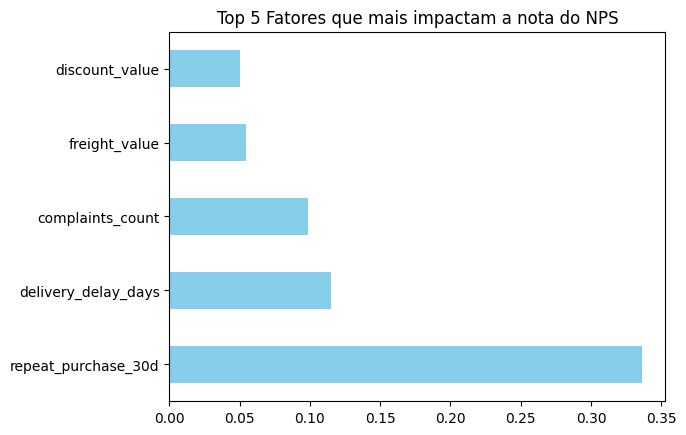

In [5]:
# Usando o Random Forest porque ele lida muito bem com regras de negócio não lineares.
# O class_weight='balanced' avisa o modelo para dar atenção extra às classes com menos volume.
modelo = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
modelo.fit(X_train, y_train)

# Gerando um gráfico rápido para ver o que o modelo achou mais importante (Feature Importance)
importancias = pd.Series(modelo.feature_importances_, index=X_train.columns)
importancias.nlargest(5).plot(kind='barh', title='Top 5 Fatores que mais impactam a nota do NPS', color='skyblue')
plt.show()

--- RELATÓRIO DE DESEMPENHO DO MODELO ---
              precision    recall  f1-score   support

    Detrator       0.85      0.98      0.91       370
      Neutro       0.73      0.27      0.39        90
    Promotor       0.93      1.00      0.96        40

    accuracy                           0.85       500
   macro avg       0.84      0.75      0.75       500
weighted avg       0.84      0.85      0.82       500



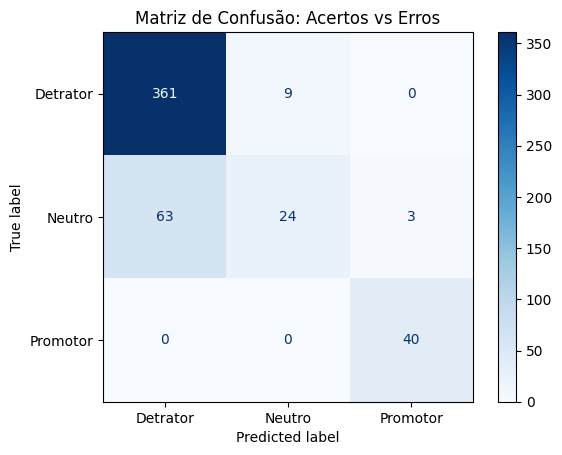

In [6]:
# ---------------------------------------------------------
# ETAPA DE AVALIAÇÃO: Será que o modelo é bom mesmo?
# ---------------------------------------------------------

# Pedimos para o modelo tentar prever as notas da nossa base de teste (que ele ainda não viu)
y_pred = modelo.predict(X_test)

# Aqui geramos o relatório de acertos.
# Nosso maior interesse é olhar para o "Recall" da linha "Detrator",
# para garantir que não estamos deixando clientes insatisfeitos passarem despercebidos.
print("--- RELATÓRIO DE DESEMPENHO DO MODELO ---")
print(classification_report(y_test, y_pred))

# Para ficar mais visual para a diretoria, vamos desenhar a Matriz de Confusão.
# Ela mostra exatamente onde o modelo acertou e onde ele trocou as bolas.
cm = confusion_matrix(y_test, y_pred, labels=modelo.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=modelo.classes_)

# Plotando o gráfico com tons de azul
disp.plot(cmap='Blues')
plt.title('Matriz de Confusão: Acertos vs Erros')
plt.show()

In [7]:
# ---------------------------------------------------------
# SIMULAÇÃO PRÁTICA: O modelo rodando no dia a dia da empresa
# ---------------------------------------------------------

# Simulando a chegada de um novo pedido que acabou de ser entregue no sistema
novo_pedido = pd.DataFrame({
    'customer_age': [35],
    'customer_tenure_months': [12],
    'order_value': [250.00],
    'items_quantity': [2],
    'discount_value': [10.00],
    'payment_installments': [3],
    'delivery_time_days': [5],
    'delivery_delay_days': [2], # Ops, tivemos 2 dias de atraso detectados pela transportadora!
    'freight_value': [15.00],
    'delivery_attempts': [2],
    'customer_service_contacts': [1],
    'resolution_time_days': [0],
    'repeat_purchase_30d': [0], # Colocada na ordem certa
    'complaints_count': [1],    # Colocada na ordem certa
    'customer_region_Nordeste': [0],
    'customer_region_Norte': [0],
    'customer_region_Sudeste': [1],
    'customer_region_Sul': [0]
})

# O sistema aplica o mesmo ajuste de escala que fizemos lá atrás
novo_pedido[colunas_numericas] = scaler.transform(novo_pedido[colunas_numericas])

# TRUQUE DE MESTRE: Força o novo dataframe a ter exatamente as mesmas colunas (e na mesma ordem) do treino
novo_pedido = novo_pedido[X_train.columns]

# O modelo faz a previsão!
previsao = modelo.predict(novo_pedido)

print("ALERTA SISTÊMICO:")
print(f"O modelo classificou este cliente com risco de ser: {previsao[0]}")
print("Ação recomendada: Acionar a equipe de Customer Experience imediatamente para contato preventivo.")

ALERTA SISTÊMICO:
O modelo classificou este cliente com risco de ser: Neutro
Ação recomendada: Acionar a equipe de Customer Experience imediatamente para contato preventivo.
